# NFL Home-Field Advantage: Deep Dive (1999–2025)

The first notebook (`analysis.ipynb`) answered *"do home teams win more?"* with win percentages for 2015–2025.
This notebook asks the harder questions a team's analytics staff would ask:

1. **Is the 2020 drop real, or just one noisy season?** (confidence intervals, significance tests)
2. **How big is home field once you remove team strength?** (a least-squares rating model)
3. **What does the betting market think home field is worth, and how has that changed?**
4. **When is home field bigger or smaller?** (rest, travel, time zones, division games, weather, roof, kickoff, altitude)
5. **If fans matter, *how*?** Did the referee and false-start gaps change when the stands were empty? (play-by-play)
6. **Do some teams really have a bigger home edge, or is that noise?** (heterogeneity test, shrinkage, split-half check)

Only pandas and numpy are used for the statistics, so every number can be traced to a formula in `hfa.py`.

In [1]:
import math, numpy as np, pandas as pd, matplotlib.pyplot as plt
import nflreadpy as nfl, polars as pl
from hfa import clean, wilson, norm_p, rating_model, adjusted_edge, mean_ci
pd.set_option("display.width", 140)
BLUE, ORANGE, INK, MUTED, GRID = "#2A5DB0", "#D9622B", "#1F2937", "#6B7280", "#E5E7EB"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.titlecolor": INK, "axes.spines.top": False, "axes.spines.right": False})
def titles(ax, title, sub):
    ax.set_title(title, loc="left", fontsize=15, fontweight="bold", pad=26)
    ax.text(0, 1.03, sub, transform=ax.transAxes, color=MUTED, fontsize=10)

## 1. Data: 27 seasons, cleaned

Same rules as before (regular season, no neutral sites, no ties, relocated teams merged), plus one new rule:
**games listed as "home" but played at a borrowed stadium are dropped** (the Saints' 2005 post-Katrina games, the Bills' Toronto series, the 2010 Metrodome roof collapse).

In [2]:
raw = nfl.load_schedules(list(range(1999, 2026))).to_pandas()
g_all = clean(raw)
print(len(g_all), "games,", g_all.season.nunique(), "seasons,", g_all.home_team.nunique(), "teams")

6878 games, 27 seasons, 32 teams


## 2. Is the 2020 drop real?

Win % with 95% Wilson intervals and average home margin by season:

In [3]:
rows = []
for s, d in g_all.groupby("season"):
    lo, hi = wilson(d.home_win.sum(), len(d)); m, mlo, mhi, _ = mean_ci(d.margin)
    rows.append((s, len(d), 100 * d.home_win.mean(), lo, hi, m))
seasons = pd.DataFrame(rows, columns=["season", "games", "win_pct", "ci_lo", "ci_hi", "margin"])
seasons.round(1)

,season,games,win_pct,ci_lo,ci_hi,margin
0,1999,248,59.7,53.5,65.6,3.1
1,2000,248,55.6,49.4,61.7,2.8
2,2001,248,54.8,48.6,60.9,2.0
3,2002,255,58.0,51.9,63.9,2.3
4,2003,255,61.6,55.5,67.3,3.6
5,2004,256,56.6,50.5,62.6,2.5
6,2005,251,59.4,53.2,65.3,3.7
7,2006,256,53.1,47.0,59.1,0.8
8,2007,255,57.6,51.5,63.6,2.9
9,2008,253,57.3,51.2,63.3,2.6


In [4]:
c = g_all[g_all.season == 2020]; o = g_all[g_all.season.between(2015, 2025) & (g_all.season != 2020)]
p1, p2 = c.home_win.mean(), o.home_win.mean(); pp = (c.home_win.sum() + o.home_win.sum()) / (len(c) + len(o))
z = (p1 - p2) / math.sqrt(pp * (1 - pp) * (1 / len(c) + 1 / len(o)))
print(f"Raw win %: 2020 {100*p1:.1f}% vs 2015-2025 excl. 2020 {100*p2:.1f}%  ->  p = {norm_p(z):.3f}")
sims = np.random.default_rng(1).binomial(len(c), 0.55, 100_000) / len(c)
print(f"Chance a 55% 'true' season lands at or below {100*p1:.1f}% by luck alone: {(sims <= p1).mean():.1%}")

Raw win %: 2020 50.4% vs 2015-2025 excl. 2020 55.0%  ->  p = 0.157
Chance a 55% 'true' season lands at or below 50.4% by luck alone: 7.9%


**Raw win % alone can't prove it.** One season is only ~250 games, so the 95% interval on any season is about ±6 points.
To get a sharper answer we need to remove the biggest source of noise: *who* was playing.

## 3. Home field after removing team strength

For each season we fit a rating model by least squares:

```
home margin = HFA + rating[home team] − rating[away team] + noise
```

Ratings sum to zero, so `HFA` is the points a home team gains against an equally good opponent. The same model fit to the **Vegas point spread** gives the market's estimate of home field.

In [5]:
rows = []
for s, d in g_all.groupby("season"):
    h, se, _, _ = rating_model(d, "margin"); hm, _, _, _ = rating_model(d, "spread_line")
    rows.append((s, h, se, hm))
adj = pd.DataFrame(rows, columns=["season", "hfa", "se", "market"])
r20 = adj[adj.season == 2020].iloc[0]
for label, others in [("2015-2025 excl. 2020", adj[adj.season.between(2015, 2025) & (adj.season != 2020)]),
                      ("all other 26 seasons", adj[adj.season != 2020])]:
    w = 1 / others.se ** 2; m = np.average(others.hfa, weights=w); se = 1 / math.sqrt(w.sum())
    z = (r20.hfa - m) / math.sqrt(r20.se ** 2 + se ** 2)
    print(f"2020: {r20.hfa:+.2f} pts vs {label}: {m:+.2f}  ->  difference {r20.hfa - m:+.2f}, p = {norm_p(z):.3f}")
d20 = g_all[g_all.season == 2020]
print(f"Vegas home field in 2020: weeks 1-8 {rating_model(d20[d20.week<=8],'spread_line')[0]:.2f} pts, weeks 9-17 {rating_model(d20[d20.week>8],'spread_line')[0]:.2f} pts")
adj.round(2)

2020: +0.13 pts vs 2015-2025 excl. 2020: +1.89  ->  difference -1.76, p = 0.031
2020: +0.13 pts vs all other 26 seasons: +2.33  ->  difference -2.20, p = 0.006
Vegas home field in 2020: weeks 1-8 1.65 pts, weeks 9-17 0.34 pts


,season,hfa,se,market
0,1999,3.06,0.75,2.36
1,2000,2.82,0.77,2.57
2,2001,2.01,0.78,2.26
3,2002,2.25,0.79,2.19
4,2003,3.60,0.83,2.46
5,2004,2.51,0.76,2.52
6,2005,3.53,0.79,2.53
7,2006,0.85,0.81,2.88
8,2007,2.84,0.79,2.46
9,2008,2.55,0.83,2.71


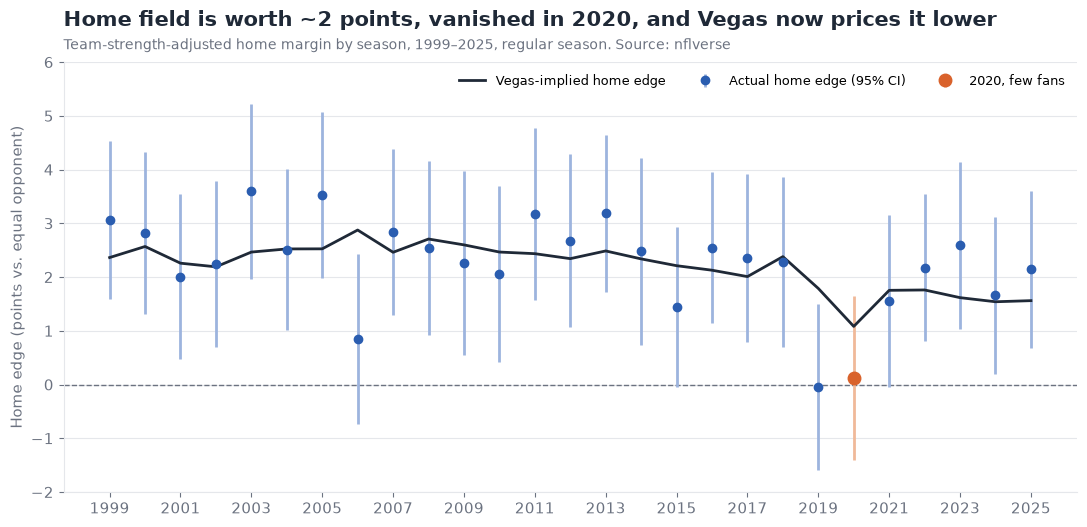

In [6]:
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.axhline(0, color=MUTED, lw=1, ls="--"); ax.grid(axis="y", color=GRID); ax.set_axisbelow(True)
normal = adj[adj.season != 2020]
ax.errorbar(normal.season, normal.hfa, yerr=1.96 * normal.se, fmt="o", color=BLUE, ecolor="#9DB4DE", elinewidth=2, capsize=0, ms=6, label="Actual home edge (95% CI)")
ax.errorbar([2020], [r20.hfa], yerr=[1.96 * r20.se], fmt="o", color=ORANGE, ecolor="#F0B999", elinewidth=2, capsize=0, ms=9, label="2020, few fans")
ax.plot(adj.season, adj.market, color=INK, lw=2, label="Vegas-implied home edge")
ax.set_ylabel("Home edge (points vs. equal opponent)"); ax.set_xticks(range(1999, 2026, 2)); ax.set_ylim(-2, 6)
ax.legend(frameon=False, loc="upper right", ncol=3, fontsize=9.5)
titles(ax, "Home field is worth ~2 points, vanished in 2020, and Vegas now prices it lower",
       "Team-strength-adjusted home margin by season, 1999–2025, regular season. Source: nflverse")
plt.tight_layout(); plt.savefig("charts/04_adjusted_hfa_vs_vegas.png", dpi=200); plt.show()

## 4. When is home field bigger or smaller?

Each game's **strength-adjusted home edge** = home margin minus the rating gap. Averaged by situation (normal-crowd seasons only, 2020 excluded):

In [7]:
g = g_all.copy(); g["edge"] = adjusted_edge(g); g = g[g.season != 2020]
early = g.gametime.fillna("13:00") < "14:00"
cold = (g.temp <= 35) & g.roof.isin(["outdoors", "open"])
groups = [
    ("All normal seasons", g.index == g.index),
    ("Visitor had 3+ more rest days", g.rest_diff <= -3), ("Equal rest", g.rest_diff == 0), ("Home had 3+ more rest days", g.rest_diff >= 3),
    ("Division game", g.div_game == 1), ("Non-division game", g.div_game == 0),
    ("Visitor travels < 500 mi", g.miles < 500), ("Visitor travels > 1,500 mi", g.miles > 1500),
    ("West visitor, 1pm ET kickoff", (g.tz_shift == 3) & early),
    ("Cold game (<=35°F, outdoors)", cold), ("Dome / closed roof", g.roof.isin(["dome", "closed"])),
    ("Primetime (7pm ET+)", g.primetime == 1), ("At Denver (altitude)", g.home_team == "DEN"),
]
sit = pd.DataFrame([(n, m.sum(), *mean_ci(g.loc[m, "edge"])[:3]) for n, m in groups], columns=["situation", "games", "edge", "lo", "hi"])
X = np.column_stack([np.ones(len(g)), g.miles / 1000, g.rest_diff.clip(-7, 7), g.div_game, g.tz_shift.abs()])
b, *_ = np.linalg.lstsq(X, g.edge, rcond=None); r = g.edge - X @ b; se = np.sqrt(np.diag(r @ r / (len(g) - X.shape[1]) * np.linalg.inv(X.T @ X)))
print(pd.DataFrame({"effect_pts": b, "ci95": 1.96 * se, "p": [norm_p(x) for x in b / se]},
                   index=["baseline", "per 1,000 miles", "per rest day", "division game", "per time zone"]).round(3))
sit.round(2)

                 effect_pts   ci95      p
baseline              2.375  0.667  0.000
per 1,000 miles       0.193  0.875  0.665
per rest day          0.198  0.117  0.001
division game        -0.584  0.626  0.067
per time zone         0.005  0.567  0.987


,situation,games,edge,lo,hi
0,All normal seasons,6626,2.33,2.04,2.61
1,Visitor had 3+ more rest days,668,0.94,0.07,1.81
2,Equal rest,4487,2.45,2.10,2.80
3,Home had 3+ more rest days,588,2.86,1.98,3.73
4,Division game,2577,1.92,1.47,2.37
5,Non-division game,4049,2.58,2.22,2.95
6,Visitor travels < 500 mi,2004,1.96,1.45,2.48
7,"Visitor travels > 1,500 mi",1316,2.97,2.34,3.60
8,"West visitor, 1pm ET kickoff",275,2.05,0.68,3.41
9,"Cold game (<=35°F, outdoors)",440,3.07,1.94,4.19


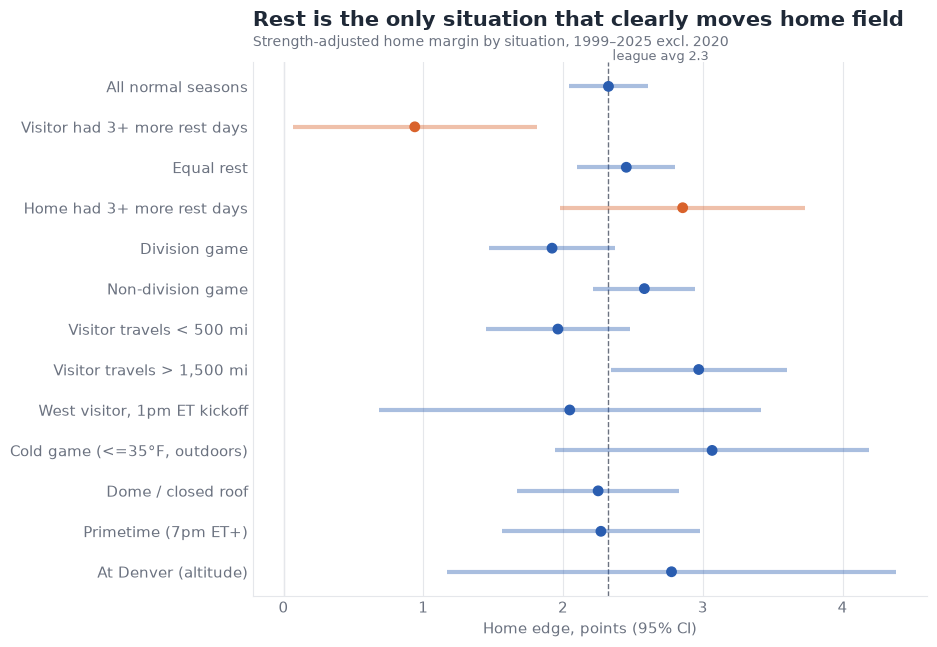

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 6.6))
s = sit.iloc[::-1].reset_index(drop=True); base = sit.edge.iloc[0]
ax.axvline(base, color=MUTED, ls="--", lw=1); ax.text(base, len(s) - 0.35, f" league avg {base:.1f}", color=MUTED, fontsize=9)
ax.axvline(0, color=GRID, lw=1)
colors = [ORANGE if n.startswith(("Visitor had", "Home had")) else BLUE for n in s.situation]
ax.hlines(s.index, s.lo, s.hi, color=[c + "66" for c in colors], lw=3)
ax.scatter(s.edge, s.index, color=colors, s=46, zorder=3)
ax.set_yticks(s.index); ax.set_yticklabels(s.situation); ax.set_xlabel("Home edge, points (95% CI)")
ax.grid(axis="x", color=GRID); ax.set_axisbelow(True); ax.tick_params(length=0)
titles(ax, "Rest is the only situation that clearly moves home field", "Strength-adjusted home margin by situation, 1999–2025 excl. 2020")
plt.tight_layout(); plt.savefig("charts/05_situations.png", dpi=200); plt.show()

## 5. If fans matter, how? Penalties and false starts (play-by-play, 2015–2025)

Two crowd theories: **(a)** noise causes visiting offenses to false-start, **(b)** crowds sway referees.
If either drove home field, the gap should shrink in 2020's empty stadiums.

*Note:* nflverse's expected-points (EPA) model already includes a home-team term, so EPA can't be used to measure home field. We use penalty counts instead.

In [9]:
ids = set(g_all.game_id)
frames = []
for s in range(2015, 2026):
    p = (nfl.load_pbp([s]).select(["game_id", "season_type", "home_team", "penalty", "penalty_team", "penalty_type", "penalty_yards"])
         .filter((pl.col("season_type") == "REG") & (pl.col("penalty") == 1)).to_pandas())
    frames.append(p[p.game_id.isin(ids)])
pen = pd.concat(frames); pen["side"] = np.where(pen.penalty_team == pen.home_team, "home", "away")
games = g_all.loc[g_all.season >= 2015, ["game_id", "season"]].set_index("game_id")
def gap(types=None, value="count"):
    p = pen if types is None else pen[pen.penalty_type.isin(types)]
    agg = "size" if value == "count" else "sum"
    w = p.groupby(["game_id", "side"]).penalty_yards.agg(agg).unstack(fill_value=0).reindex(games.index, fill_value=0)
    return (w.get("away", 0) - w.get("home", 0)).rename("gap").to_frame().join(games)
rows = []
for name, types, val in [("All penalties", None, "count"), ("Penalty yards", None, "yards"), ("False starts", ["False Start"], "count"),
                         ("Delay of game", ["Delay of Game"], "count"), ("Offensive holding", ["Offensive Holding"], "count"),
                         ("Def. pass interference", ["Defensive Pass Interference"], "count")]:
    d = gap(types, val); n = d[d.season != 2020].gap; c = d[d.season == 2020].gap
    se = math.sqrt(n.var() / len(n) + c.var() / len(c)); z = (c.mean() - n.mean()) / se
    rows.append((name, n.mean(), c.mean(), c.mean() - n.mean(), norm_p(z)))
pens = pd.DataFrame(rows, columns=["visitor minus home, per game", "normal seasons", "2020", "change", "p"])
print("With 6 tests, a Bonferroni-corrected threshold is p < 0.008.")
pens.round(3)

With 6 tests, a Bonferroni-corrected threshold is p < 0.008.


,"visitor minus home, per game",normal seasons,2020,change,p
0,All penalties,0.353,0.381,0.028,0.889
1,Penalty yards,3.138,3.143,0.004,0.998
2,False starts,-0.051,0.143,0.194,0.041
3,Delay of game,0.080,0.012,-0.068,0.129
4,Offensive holding,-0.077,0.139,0.216,0.016
5,Def. pass interference,0.065,0.095,0.030,0.679


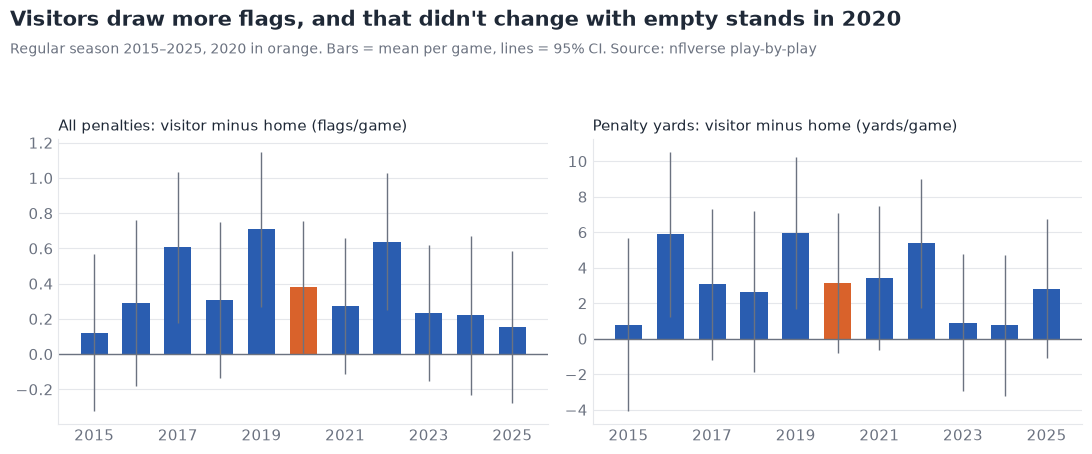

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (name, val, unit) in zip(axes, [("All penalties", "count", "flags"), ("Penalty yards", "yards", "yards")]):
    d = gap(None, val); by = d.groupby("season").gap.agg(["mean", "std", "size"]); ci = 1.96 * by["std"] / np.sqrt(by["size"])
    col = [ORANGE if s == 2020 else BLUE for s in by.index]
    ax.bar(by.index, by["mean"], color=col, width=0.65); ax.errorbar(by.index, by["mean"], yerr=ci, fmt="none", ecolor=MUTED, elinewidth=1)
    ax.axhline(0, color=MUTED, lw=1); ax.set_title(f"{name}: visitor minus home ({unit}/game)", loc="left", fontsize=11, color=INK)
    ax.set_xticks(by.index[::2]); ax.grid(axis="y", color=GRID); ax.set_axisbelow(True); ax.tick_params(length=0)
fig.suptitle("Visitors draw more flags, and that didn't change with empty stands in 2020", x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.01, 0.885, "Regular season 2015–2025, 2020 in orange. Bars = mean per game, lines = 95% CI. Source: nflverse play-by-play", color=MUTED, fontsize=10)
plt.tight_layout(rect=(0, 0, 1, 0.86)); plt.savefig("charts/06_penalty_gap.png", dpi=200); plt.show()

## 6. Do some teams really have a bigger home edge?

A team's **home boost** = how much better it does than expected at home, minus how it does on the road (both strength-adjusted).
If teams truly differ, the spread of boosts should be wider than sampling noise alone would produce, and a team's boost should repeat from one era to the next.

In [11]:
H = g.edge.mean(); rows = []
for t in sorted(g.home_team.unique()):
    h = g.loc[g.home_team == t, "edge"]; a = g.loc[g.away_team == t, "edge"]
    rows.append((t, (h.mean() - H) + (a.mean() - H), math.sqrt(h.var() / len(h) + a.var() / len(a))))
teams = pd.DataFrame(rows, columns=["team", "boost", "se"]).set_index("team")
Q = (((teams.boost - teams.boost.mean()) / teams.se) ** 2).sum(); k = len(teams) - 1
zq = ((Q / k) ** (1 / 3) - (1 - 2 / (9 * k))) / math.sqrt(2 / (9 * k))
tau2 = max(teams.boost.var() - (teams.se ** 2).mean(), 0); teams["shrunk"] = teams.boost.mean() + tau2 / (tau2 + teams.se ** 2) * (teams.boost - teams.boost.mean())
halves = []
for lo, hi in [(1999, 2011), (2012, 2025)]:
    d = g[g.season.between(lo, hi)]; Hh = d.edge.mean()
    halves.append(pd.Series({t: (d.loc[d.home_team == t, "edge"].mean() - Hh) + (d.loc[d.away_team == t, "edge"].mean() - Hh) for t in teams.index}))
print(f"Observed SD of team boosts {teams.boost.std():.2f} pts vs. {math.sqrt((teams.se**2).mean()):.2f} expected from noise alone")
print(f"Heterogeneity test: Q = {Q:.1f} on {k} df, p ≈ {0.5*math.erfc(zq/math.sqrt(2)):.2f}")
print(f"Split-half correlation (1999-2011 vs 2012-2025): {halves[0].corr(halves[1]):+.2f}")
teams.sort_values("boost", ascending=False).round(2)

Observed SD of team boosts 1.23 pts vs. 1.16 expected from noise alone
Heterogeneity test: Q = 35.6 on 31 df, p ≈ 0.26
Split-half correlation (1999-2011 vs 2012-2025): -0.11


,boost,se,shrunk
team,,,
MIN,1.78,1.12,0.22
BAL,1.65,1.14,0.19
GB,1.51,1.17,0.17
SF,1.43,1.14,0.17
JAX,1.19,1.17,0.13
CHI,1.13,1.11,0.14
DET,1.09,1.08,0.14
KC,1.01,1.20,0.11
DEN,0.91,1.21,0.10


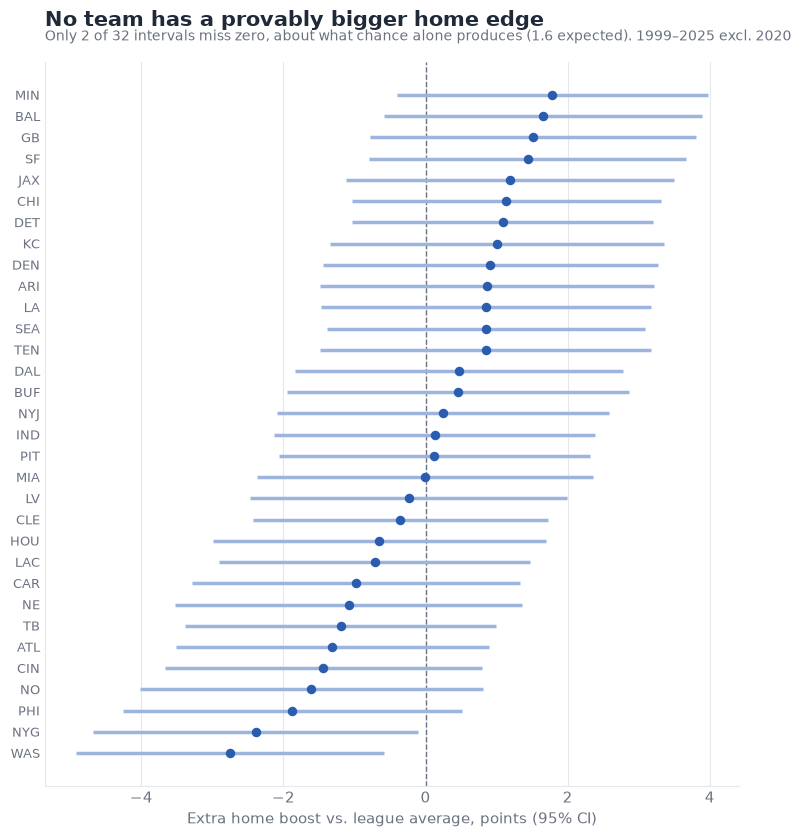

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 8.5))
t = teams.sort_values("boost").reset_index()
ax.axvline(0, color=MUTED, ls="--", lw=1)
ax.hlines(t.index, t.boost - 1.96 * t.se, t.boost + 1.96 * t.se, color="#9DB4DE", lw=2.5)
ax.scatter(t.boost, t.index, color=BLUE, s=34, zorder=3)
ax.set_yticks(t.index); ax.set_yticklabels(t.team, fontsize=9); ax.tick_params(length=0)
ax.set_xlabel("Extra home boost vs. league average, points (95% CI)"); ax.grid(axis="x", color=GRID); ax.set_axisbelow(True)
titles(ax, "No team has a provably bigger home edge", "Only 2 of 32 intervals miss zero, about what chance alone produces (1.6 expected). 1999–2025 excl. 2020")
plt.tight_layout(); plt.savefig("charts/07_team_boosts.png", dpi=200); plt.show()

## Findings

1. **Home field is worth about 2.3 points** against an equal opponent (1999–2025, normal seasons), and it has slowly shrunk: ~2.6 pts in 1999–2009, ~2.2 in 2010–2019, ~2.0 since 2021.
2. **2020 really was different.** Raw win % alone can't prove it (p = 0.16), but after removing team strength, 2020's home edge was **+0.1 pts vs ~+2.2** in other seasons (**p = 0.006**). 2019 was also near zero, so 2020 is the clearest case, not the only low year.
3. **Vegas learned in real time.** The market priced home field at ~1.7 pts in weeks 1–8 of 2020 and ~0.3 pts in weeks 9–17. It has priced it lower ever since (~1.6 pts, vs ~2.5 in the 2000s).
4. **Rest is the situation that matters most:** each extra day of rest is worth ~0.2 pts (p = 0.001). When the visitor has 3+ more days of rest, home field drops to ~0.9 pts. Division games trim it ~0.6 pts (familiarity; p = 0.07).
5. **Popular theories don't hold up:** cold weather, domes, primetime, Denver's altitude and West-coast "body clock" trips show no reliable extra edge once team strength is removed.
6. **Crowds don't seem to work through the referees.** Visitors draw ~0.35 more flags and ~3 more penalty yards per game, and that gap was **identical in 2020**. False-start and other gaps showed no change that survives a multiple-testing correction.
7. **Team-specific home edges are mostly noise.** The spread across teams is about what chance alone produces (p ≈ 0.26), and a team's boost in one era doesn't predict the next (r = −0.11). Miami's +26-point gap in the simple 2015–2025 win-% table is a small-sample streak, not a real Miami effect.

**Limitations:** 2020 had *some* fans in some stadiums (attendance isn't in this data); the rating model assumes one strength per team per season; situations overlap (e.g. division games are shorter trips), which is why rest/travel/division are also fit jointly above.